# 01 — Data profiling and cleaning

**Dataset:** `data/dsc_test_case.csv`. One row = one customer offered an insurance campaign in a given month.

The brief asks about **Policy** and **Payment** data. Both live in this single file:

| Brief term | Column | Meaning |
|---|---|---|
| Policy | `label` | 0 = rejected the offer, 1 = bought PA (personal accident) insurance, 2 = bought life insurance |
| Payment | `easypymt_last_30d` | total payments the customer made from their bank account in the 30 days **before** the campaign |

⚠️ `easypymt_last_30d` is payment *behaviour* before the offer, **not** the premium paid for the policy.
The dataset has no premium, sum-assured or policy-status column.

This notebook checks the data against its definition, finds problems, and records every cleaning decision.
The cleaning itself lives in `src/prep.py` so the analysis notebook and the report use exactly the same rules.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import prep

pd.set_option("display.max_columns", 50, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "font.family": "sans-serif"})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"

raw = prep.load_raw()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

215,993 rows x 26 columns


,campaign_month,marital_sta,main_occupation,customer_segment,gender,have_acc_planet,have_cc,scb_payroll,num_children,age,income,maxosdc_last_30d,dcspend_last_30d,easypymt_last_30d,savacc_bal,currentacc_bal,avg_savaccbal_30d,avg_currentaccbal_30d,mob,inflow30d,outflow30d,inflow1_15,outflow1_15,net_flow_30d,net_flow_15d,label
0,Mar,โสด,Salary man,Lower Mass,Female,N,N,Y,0.0,41.0,11017.00,15242.93,0.0,210.0,6442.93,0.0,2034.46,0.0,77.0,0.00,0.00,0.00,0.00,0.0,0.0,0
1,Jul,สมรส,Salary man,Mass,Female,N,N,N,1.0,46.0,15140.15,0.00,0.0,0.0,0.00,0.0,0.00,0.0,14.0,0.00,0.00,0.00,0.00,0.0,0.0,0
2,Jan,โสด,Self-employed,Lower Mass,Male,N,N,N,0.0,36.0,452.87,1205.00,0.0,1486.0,1099.71,0.0,217.77,0.0,37.0,13558.67,14454.97,13558.67,14454.97,-896.3,-896.3,0
3,Nov,โสด,Salary man,Mass,Female,N,N,N,0.0,38.0,12036.17,0.00,0.0,0.0,45554.61,0.0,45554.61,0.0,165.0,0.00,0.00,0.00,0.00,0.0,0.0,0
4,Oct,สมรสจด ทะเบียน,Salary man,Mass,Female,N,N,N,0.0,41.0,25000.00,1896.51,0.0,5900.0,1224.51,0.0,1238.59,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,0


## 1. Data definition vs. the actual columns

In [2]:
dd = pd.read_excel(prep.DATA_DIR / "data definition.xlsx", header=1).iloc[:, 1:]
dd.columns = ["field", "declared_type", "definition"]
dd["actual_dtype"] = dd["field"].map(raw.dtypes.astype(str))
dd["in_csv"] = dd["field"].isin(raw.columns)
dd

,field,declared_type,definition,actual_dtype,in_csv
0,campaign_month,string,Abbreviated Name of the Campaign Month,str,True
1,marital_sta,string,Marital Status,str,True
2,main_occupation,string,Main Occupation Class (might not really updated),str,True
3,customer_segment,string,"Customer Segment - Lower Mass, Mass, Upper Mass",str,True
4,gender,string,Customer Gender,str,True
5,have_acc_planet,string,Flag whether the customer has travel card acco...,str,True
6,have_cc,string,Flag whether the customer used to has Credit C...,str,True
7,scb_payroll,string,Flag whether the customer used to has Payroll ...,str,True
8,num_children,integer,Total num ber of children.,float64,True
9,age,double,Current Age at the campaign begins.,float64,True


All 26 defined fields are in the file and their types match (integers such as `age`, `mob` and `num_children` load as floats only because they contain missing values).

One wording error in the definition: `outflow30d` and `outflow1_15` say *"Inflow = cash out…"*; it should read *"Outflow = cash out…"*. The data itself is consistent with outflow (see §4).

## 2. Missing values and duplicates

In [3]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(),
    "zero_%": ((raw == 0).mean() * 100).round(1),
})
profile

,dtype,missing,missing_%,unique,zero_%
campaign_month,str,0,0.00,12,0.0
marital_sta,str,4635,2.15,8,0.0
main_occupation,str,1500,0.69,10,0.0
customer_segment,str,1500,0.69,3,0.0
gender,str,1500,0.69,2,0.0
have_acc_planet,str,2401,1.11,2,0.0
have_cc,str,1500,0.69,2,0.0
scb_payroll,str,1500,0.69,2,0.0
num_children,float64,1500,0.69,9,96.2
age,float64,1500,0.69,39,0.0


In [4]:
no_demo = raw["age"].isna()
no_fin = raw["income"].isna()
print("rows missing demographics:", no_demo.sum())
print("rows missing financials:  ", no_fin.sum())
print("missing demographics but has financials:", (no_demo & ~no_fin).sum())
print("label is never missing:", raw["label"].notna().all())

dup = raw.duplicated()
print("\nexact duplicate rows (extra copies):", dup.sum())
print("labels among the extra copies:", raw.loc[dup, "label"].value_counts().to_dict())
filled = raw.notna().sum(axis=1)
print("\nextra copies by number of filled fields (out of 26):")
print(filled[dup].value_counts().sort_index().rename_axis("filled fields").to_frame("rows"))

rows missing demographics: 1500
rows missing financials:   2401
missing demographics but has financials: 0
label is never missing: True



exact duplicate rows (extra copies): 2173
labels among the extra copies: {0: 2173}

extra copies by number of filled fields (out of 26):
               rows
filled fields      
2              1496
10              444
26              233


### Rule for duplicates

There is **no customer ID**, only the campaign month, so two identical rows could be two real customers whose IDs were masked. Dropping them would delete real data.
The duplicates fall into three clear groups:
- **2 of 26 fields filled** (only month and label): 1,496 rows.
- **10 of 26 filled** (demographics, no financials): 444 rows.
- **all 26 filled**: 233 rows.

**Decision:** drop a duplicate only when it is **mostly null** (fewer than half of its fields filled). Such a row adds nothing beyond a rejection count. The **233 fully populated duplicates are kept**.

In production, de-duplication should happen **upstream, before customer IDs and personal data are masked**, while a real key still exists.

In [5]:
mostly_null = filled < raw.shape[1] / 2
print("dropped (duplicate and mostly null):", (dup & mostly_null).sum())
print("kept (duplicate but fully populated):", (dup & ~mostly_null).sum())
print(f"acceptance rate: raw {raw['label'].gt(0).mean():.3%} -> after drop {raw.loc[~(dup & mostly_null), 'label'].gt(0).mean():.3%}")

dropped (duplicate and mostly null): 1940
kept (duplicate but fully populated): 233
acceptance rate: raw 1.214% -> after drop 1.225%


**Findings**
- Missing values are **block-shaped**, not random: a row is missing either nothing, all financial fields, or all demographic *and* financial fields. That points to a join to a customer/account table that failed for some customers.
- 1,940 mostly-null duplicates are dropped and 233 fully populated ones kept (rule above). All duplicates are rejections, so the acceptance rate moves only from 1.214% to 1.225%.
- After the drop only 4 rows remain without demographics: most of the empty rows were duplicates.

## 3. Policy (`label`) — the target

,customers,share_%
label,,
Rejected,213371,98.79
PA (personal accident),1634,0.76
Life,988,0.46


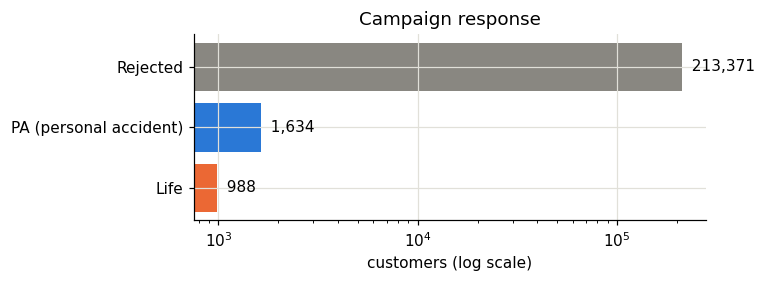

In [6]:
lab = raw["label"].map(prep.LABELS).value_counts()
display(pd.DataFrame({"customers": lab, "share_%": (lab / lab.sum() * 100).round(2)}))

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(lab.index[::-1], lab.values[::-1], color=[ORANGE, BLUE, GREY])  # Life, PA, Rejected
ax.set_xscale("log"); ax.set_xlabel("customers (log scale)"); ax.set_title("Campaign response")
for y, v in enumerate(lab.values[::-1]):
    ax.text(v, y, f"  {v:,}", va="center")
plt.show()

Only **1.2%** of customers accepted (0.76% PA, 0.46% life). The data is heavily imbalanced, so:
- the analysis talks about **rates** (per 100 customers), never raw counts;
- small groups (e.g. *Entertainer*, 244 people) can show large rates by chance, so differences are tested before they are called real (notebook 02).

## 4. Consistency checks between columns

In [7]:
fin = raw.dropna(subset=["inflow30d"])
checks = {
    "inflow1_15 == inflow30d (15-day equals 30-day)": (fin["inflow1_15"] == fin["inflow30d"]).mean(),
    "outflow1_15 == outflow30d": (fin["outflow1_15"] == fin["outflow30d"]).mean(),
    "net_flow_15d == net_flow_30d": (fin["net_flow_15d"] == fin["net_flow_30d"]).mean(),
    "net_flow_30d == inflow30d - outflow30d": ((fin["inflow30d"] - fin["outflow30d"] - fin["net_flow_30d"]).abs() < 0.01).mean(),
    "currentacc_bal is only 0 or 1": fin["currentacc_bal"].isin([0, 1]).mean(),
}
pd.Series(checks, name="share of rows where true").round(4).to_frame()

,share of rows where true
inflow1_15 == inflow30d (15-day equals 30-day),1.0
outflow1_15 == outflow30d,1.0
net_flow_15d == net_flow_30d,1.0
net_flow_30d == inflow30d - outflow30d,1.0
currentacc_bal is only 0 or 1,1.0


**Findings**
- The three **15-day columns are exact copies of the 30-day columns** in 100% of rows: an extraction bug. They carry no extra information → **dropped**.
- `net_flow_30d = inflow30d − outflow30d` holds in 100% of rows that have financials, which confirms that inflow and outflow are labelled correctly in the data (only the definition text is wrong).
- `currentacc_bal` only takes the values 0 and 1 (98.8% zero) and cannot be a balance → **dropped**. Current accounts are rare in this mass-market base anyway (`avg_currentaccbal_30d` is also 98.8% zero; kept, but not used).

## 5. Plausibility of individual values

In [8]:
num = ["age", "income", "num_children", "mob", "easypymt_last_30d", "savacc_bal", "avg_savaccbal_30d",
       "maxosdc_last_30d", "dcspend_last_30d", "inflow30d", "outflow30d", "net_flow_30d"]
raw[num].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(1)

,count,mean,std,min,1%,25%,50%,75%,99%,max
age,214493.0,37.8,9.6,23.0,24.0,30.0,36.0,45.0,59.0,61.0
income,213592.0,16867.4,19992.8,0.0,79.4,4365.0,12252.6,21166.6,101655.6,199625.7
num_children,214493.0,0.0,0.3,0.0,0.0,0.0,0.0,0.0,1.0,21.0
mob,213592.0,54.6,66.4,0.0,0.0,0.0,40.0,77.0,246.0,887.0
easypymt_last_30d,213592.0,1196.4,8443.9,0.0,0.0,88.0,373.0,925.0,13192.1,2000000.0
savacc_bal,213592.0,20856.3,94906.7,0.0,0.0,7.4,800.7,7557.9,415511.4,4793828.3
avg_savaccbal_30d,213592.0,15175.7,69798.0,0.0,0.0,122.9,992.9,4643.6,305169.2,2471112.6
maxosdc_last_30d,213592.0,11354.8,58449.1,0.0,0.0,0.0,0.0,4037.9,210890.4,4374289.2
dcspend_last_30d,213592.0,165.4,7403.8,-87030.9,0.0,0.0,0.0,0.0,2034.3,1852987.9
inflow30d,213592.0,25289.8,122904.8,0.0,0.0,0.0,0.0,16907.5,356322.8,21471692.2


In [9]:
print("age range:", raw["age"].min(), "-", raw["age"].max())
print("income == 0:", (raw["income"] == 0).sum())
print("num_children > 10:", (raw["num_children"] > 10).sum(), "| max:", raw["num_children"].max())
print("mob (months on book) longer than adult life, mob > (age-15)*12:", (raw["mob"] > (raw["age"] - 15) * 12).sum(),
      "| max mob:", raw["mob"].max(), "months")
print("negative debit-card spend:", (raw["dcspend_last_30d"] < 0).sum())
print("easypymt max:", raw["easypymt_last_30d"].max())

age range: 23.0 - 61.0
income == 0: 342
num_children > 10: 2 | max: 21.0
mob (months on book) longer than adult life, mob > (age-15)*12: 839 | max mob: 887.0 months
negative debit-card spend: 17
easypymt max: 2000000.0


**Findings**
- Age is 23–61: the campaign targeted working-age customers.
- 839 rows have `mob` longer than the customer could have been an adult (max 887 months ≈ 74 years) → `mob` set to missing for those rows only.
- 2 rows have more than 10 children (max 21) → set to missing.
- 342 customers have income = 0 → kept and flagged; likely unreported income.
- A handful of negative debit-card spends (refunds/reversals) → kept.
- Money columns are **very right-skewed** (mean ≫ median; e.g. easypymt median 373 vs max 2,000,000). The analysis uses **medians and bands**, not means.

## 6. Payment (`easypymt_last_30d`) distribution

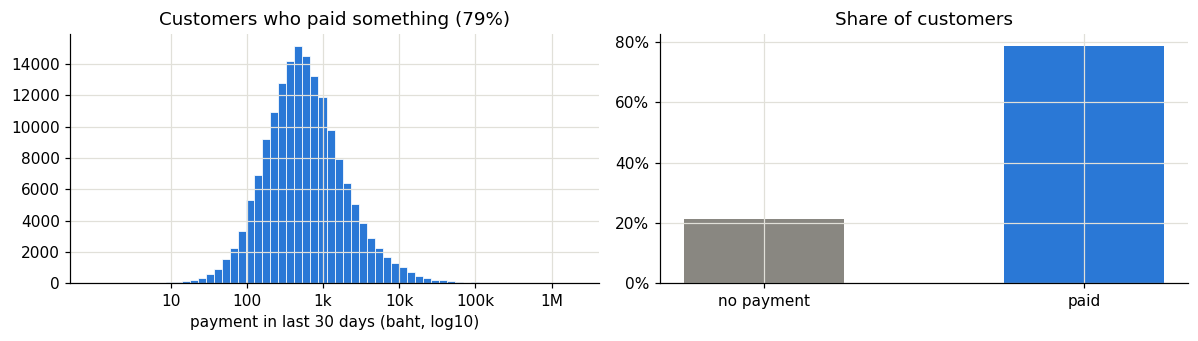

In [10]:
p = raw["easypymt_last_30d"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(np.log10(p[p > 0]), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("payment in last 30 days (baht, log10)")
axes[0].set_xticks([1, 2, 3, 4, 5, 6]); axes[0].set_xticklabels(["10", "100", "1k", "10k", "100k", "1M"])
axes[0].set_title(f"Customers who paid something ({(p > 0).mean():.0%})")
share_zero = (p == 0).mean()
axes[1].bar(["no payment", "paid"], [share_zero, 1 - share_zero], color=[GREY, BLUE], width=0.5)
axes[1].set_title("Share of customers"); axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

21% of customers made **no payment at all** in the 30 days before the offer. That is a distinct group (likely dormant or offline customers), so the payment bands keep 0 as its own band.
The rest are roughly log-normal around a few hundred baht: typical bill/top-up payments.

## 7. Campaign month

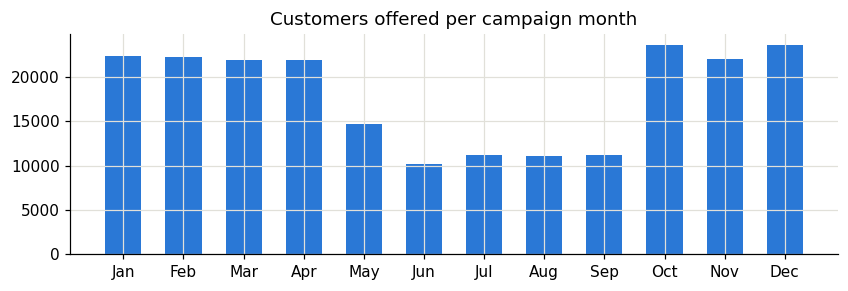

In [11]:
m = raw["campaign_month"].value_counts().reindex(prep.MONTHS)
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(m.index, m.values, color=BLUE, width=0.6); ax.set_title("Customers offered per campaign month")
plt.show()

The month has **no year**. Oct–Apr each have ~22k customers and May–Sep ~11k, so the campaign was either scaled down mid-year or the file mixes two campaign waves.
Month is treated as a label for comparison only; I don't claim a seasonal trend from one unknown year.

## 8. Apply the cleaning

In [12]:
df, log = prep.clean(raw)
print(f"clean: {df.shape[0]:,} rows x {df.shape[1]} columns")
log

clean: 214,053 rows x 35 columns


,step,rows_affected,action
0,"exact duplicate rows, mostly null",1940,dropped (all are label 0)
1,"exact duplicate rows, fully populated",233,kept (may be distinct customers)
2,redundant columns,0,"dropped inflow1_15, outflow1_15, net_flow_15d,..."
3,no demographic fields,4,kept; shown as 'Unknown' in demographic splits
4,no financial fields,461,kept; excluded from financial/payment splits
5,mob longer than customer's adult life,839,mob set to NaN
6,num_children > 10,2,set to NaN
7,income = 0,342,"kept, flagged (may be unreported income)"


## Summary of data quality

| Issue | Rows | Decision |
|---|---|---|
| Exact duplicates, mostly null (< 13 of 26 fields) | 1,940 | dropped |
| Exact duplicates, fully populated | 233 | kept (no key to prove they are the same customer) |
| 15-day flow columns identical to 30-day | all | 3 columns dropped |
| `currentacc_bal` only 0/1 | all | dropped |
| Missing financial fields (block) | 461 after de-dup | kept; skipped in financial splits |
| `mob` longer than adult life | 839 | `mob` → missing |
| `num_children` > 10 | 2 | → missing |
| Income = 0 | 342 | kept, flagged |
| No premium / policy-status column | — | stated as a limitation |
| No year on campaign month | — | no seasonality claims |

Clean dataset: **214,053 customers**, 1.22% acceptance (0.76% PA, 0.46% life).